# Module 06: Final Data Science Project
## Project: Customer Churn Prediction & Analysis

### Step 1 – Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


### Step 3 – Upload and load the dataset

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Customer Churn Dataset Loaded Successfully!")

display(df.head())

Customer Churn Dataset Loaded Successfully!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 4 – Understand the dataset

In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape:
(7043, 21)

Number of Rows: 7043
Number of Columns: 21


### Step 5 – Explore dataset information

### 5.1 – Dataset information

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 5.2 – Statistical summary

In [5]:
display(df.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### 5.3 – Check missing values

In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### 5.4 – Check duplicate records

In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


### 5.5 – Check Churn distribution

In [8]:
print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### Step 6 – Data Cleaning and Preprocessing
The IBM Telco dataset has a few things we need to handle:
- TotalCharges is stored as text instead of numeric data.
- Some TotalCharges values contain blank spaces.
- customerID is an identifier, not a useful prediction feature.

### 6.1 – Check column data types

In [9]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


### 6.2 – Convert TotalCharges into numeric format

In [10]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges converted successfully!")

TotalCharges converted successfully!


### 6.3 – Check missing values again

In [11]:
print("Missing Values After Conversion:")
print(df.isnull().sum())

Missing Values After Conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


### 6.4 – Handle missing values

In [12]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values handled successfully!")

Missing values handled successfully!


### 6.5 – Check duplicate records

In [13]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


### 6.6 – Remove unnecessary customer ID column

In [14]:
df.drop("customerID", axis=1, inplace=True)

print("Customer ID column removed successfully!")

Customer ID column removed successfully!


### 6.7 – Verify the cleaned dataset

In [15]:
print("Final Dataset Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nUpdated Data Types:")
print(df.dtypes)

Final Dataset Shape: (7043, 20)

Remaining Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Updated Data Types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod      

### Step 7 – Explore customer churn distribution

In [16]:
print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Visualize customer churn

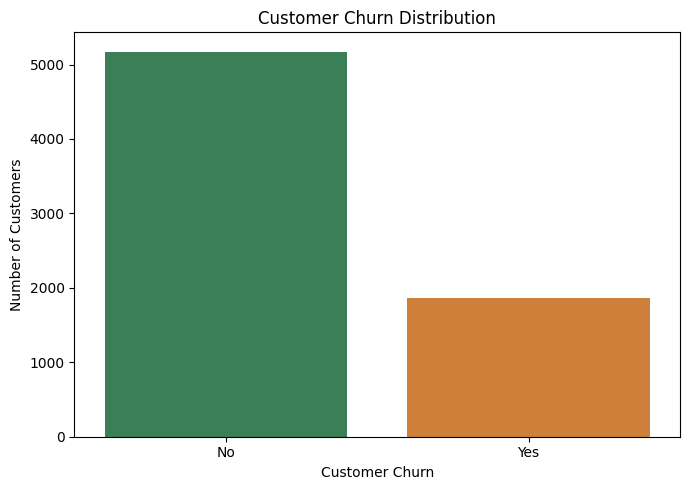

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette={
        "No": "#2E8B57",
        "Yes": "#E67E22"
    },
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Step 8 – Analyze customer demographics

### 8.1 – Gender distribution

Customer Gender Distribution:
gender
Male      3555
Female    3488
Name: count, dtype: int64


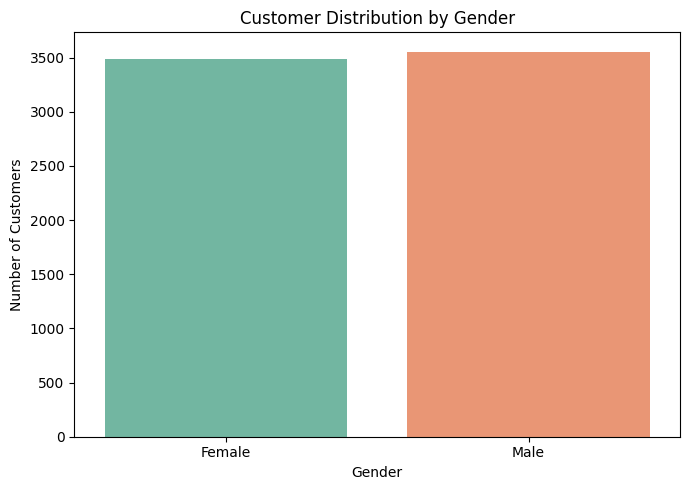

In [18]:
print("Customer Gender Distribution:")
print(df["gender"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="gender",
    palette="Set2",
    legend=False
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 8.2 – Senior citizen distribution
The SeniorCitizen column uses:
- 0 = Not a senior citizen
- 1 = Senior citizen

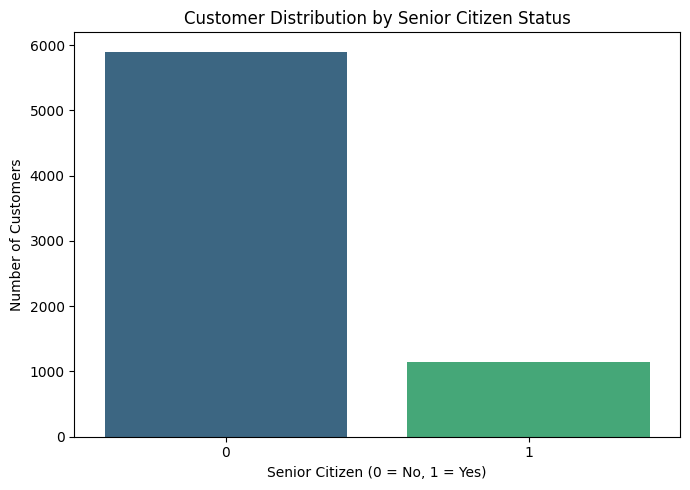

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="SeniorCitizen",
    palette="viridis",
    legend=False
)

plt.title("Customer Distribution by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Step 9 – Analyze churn by customer characteristics

### 9.1 – Churn by gender

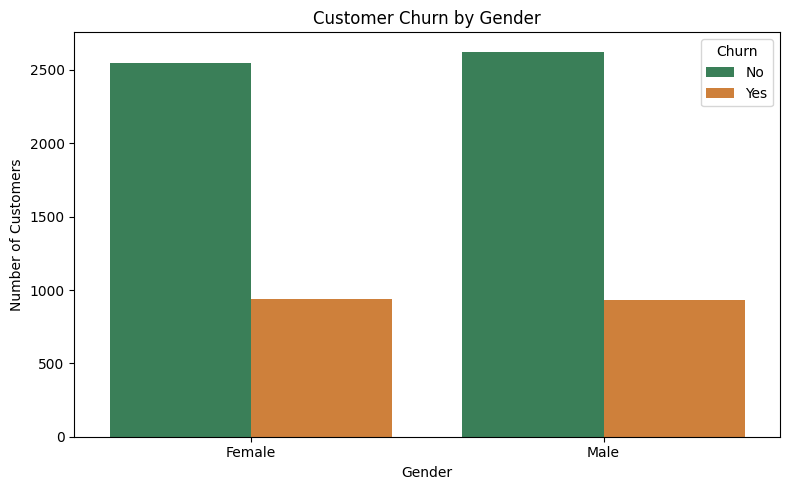

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn",
    palette={
        "No": "#2E8B57",
        "Yes": "#E67E22"
    }
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 9.2 – Churn by contract type

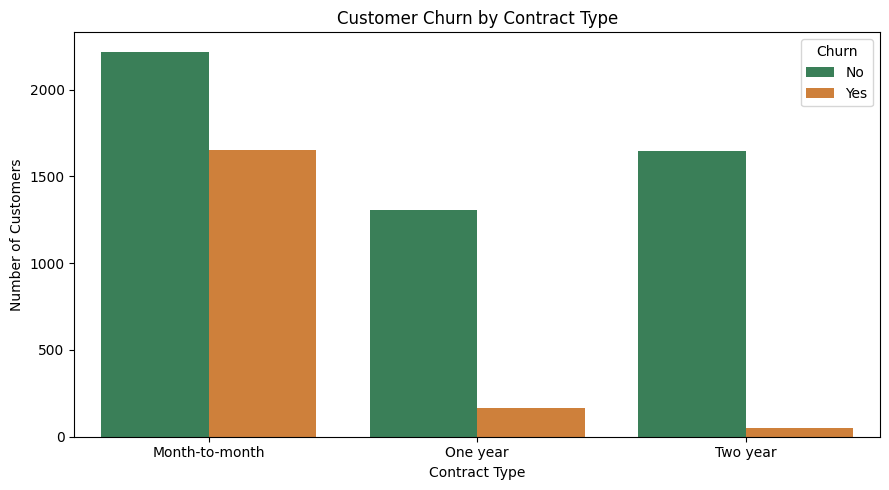

In [21]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette={
        "No": "#2E8B57",
        "Yes": "#E67E22"
    }
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Step 10 – Analyze customer charges and tenure

### 10.1 – Monthly charges distribution

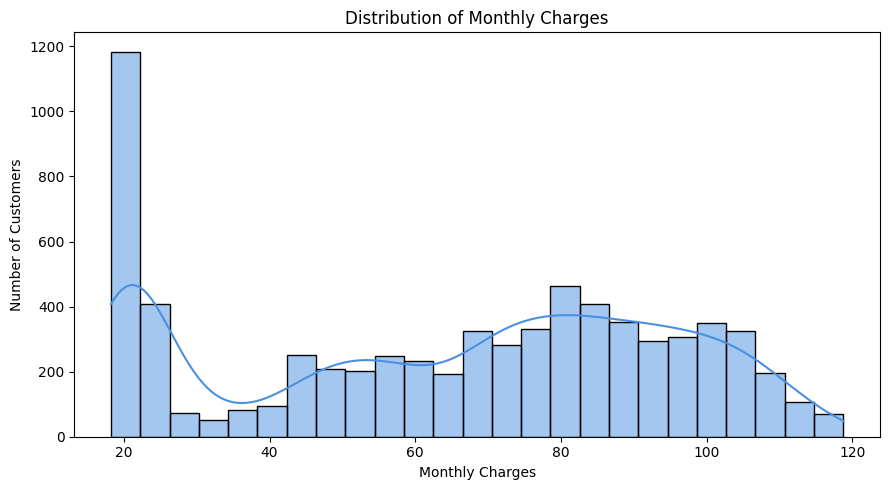

In [22]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=25,
    kde=True,
    color="#4A90E2"
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 10.2 – Customer tenure distribution

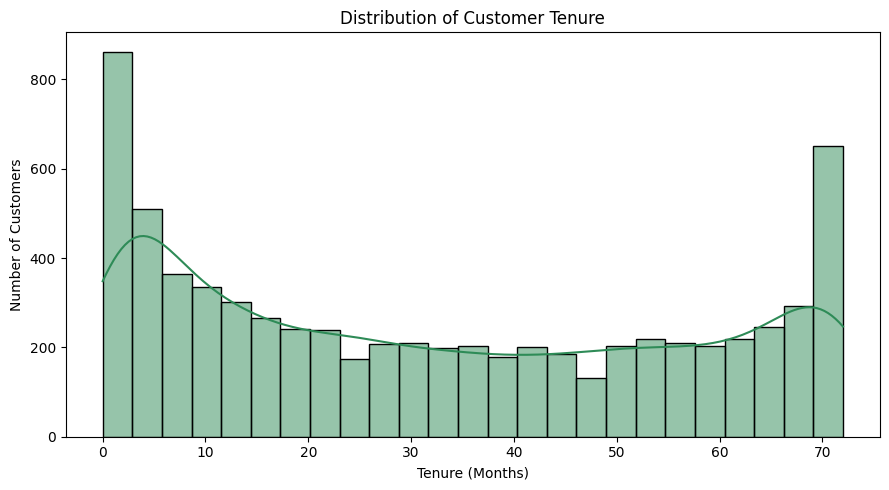

In [23]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=25,
    kde=True,
    color="#2E8B57"
)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 10.3 – Tenure vs Churn

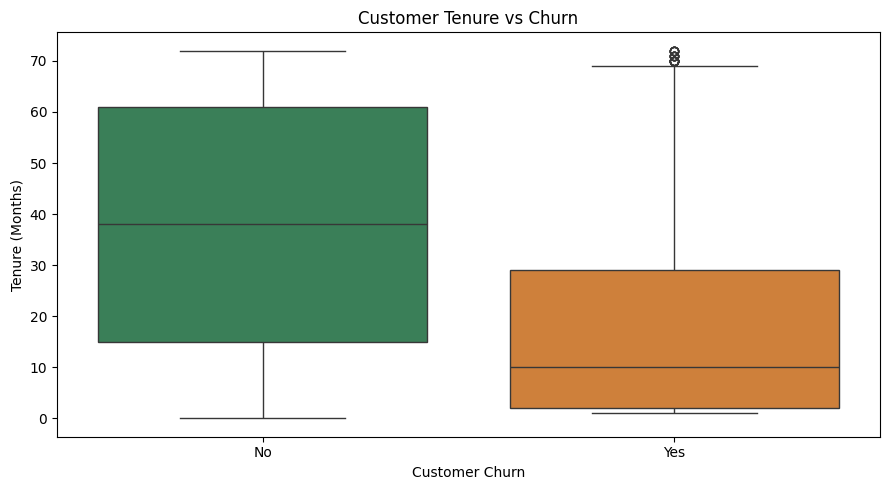

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette={
        "No": "#2E8B57",
        "Yes": "#E67E22"
    },
    legend=False
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

### Step 11 – Analyze internet services

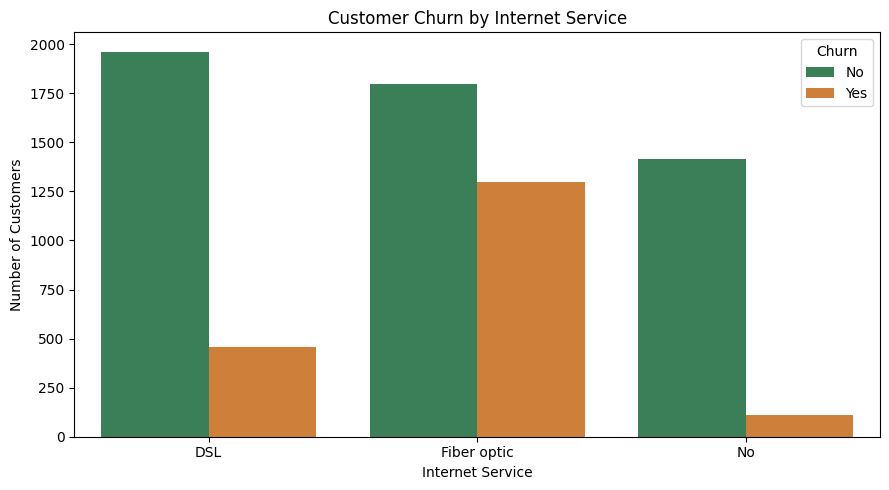

In [25]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    palette={
        "No": "#2E8B57",
        "Yes": "#E67E22"
    }
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Step 12 – Numerical analysis of churn

In [26]:
print("Customer Churn Analysis:\n")

print(
    df.groupby("Churn")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean().round(2)
)

Customer Churn Analysis:

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80


### Step 13 – Prepare input features and target variable

In [27]:
X = df.drop("Churn", axis=1)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Input Features Shape: (7043, 19)
Target Variable Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


### Step 14 – Convert categorical data into numerical data

In [28]:
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Categorical Data Encoded Successfully!")

print("Updated Dataset Shape:", X.shape)

display(X.head())

Categorical Data Encoded Successfully!
Updated Dataset Shape: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


### Step 15 – Split the dataset into training and testing data

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 30)
Testing Features: (1409, 30)

Training Target: (5634,)
Testing Target: (1409,)


### Step 16 – Build a Machine Learning model

In [30]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

print("Random Forest Model Created Successfully!")

Random Forest Model Created Successfully!


### Step 17 – Train the model

In [31]:
model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


### Step 18 – Make predictions using the trained model

In [32]:
y_pred = model.predict(X_test)

print("Predictions Generated Successfully!")
print("\nFirst 10 Predictions:")
print(y_pred[:10])

Predictions Generated Successfully!

First 10 Predictions:
[0 1 0 0 0 1 0 0 0 0]


### Step 19 – Evaluate model accuracy

In [33]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 80.62 %


### Step 20 – Classification Report
Now we'll calculate Precision, Recall and F1-score.

In [34]:
from sklearn.metrics import classification_report

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



### Step 21 – Confusion Matrix
A confusion matrix helps us understand correct and incorrect predictions

In [35]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[937  98]
 [175 199]]


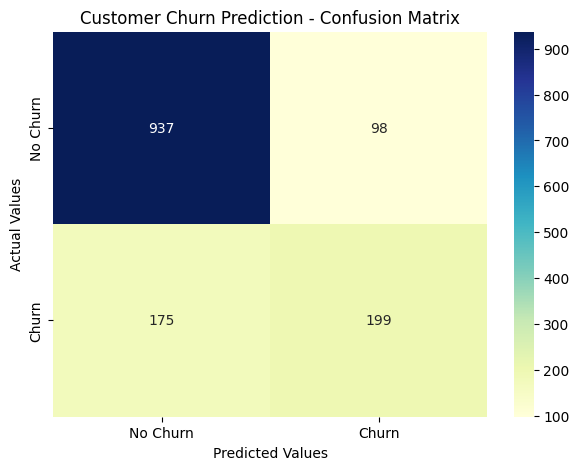

In [36]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Customer Churn Prediction - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

### Step 22 – Model Evaluation Interpretation

The Random Forest Classifier was evaluated using Accuracy, Precision, Recall, F1-score and a Confusion Matrix.

The evaluation metrics helped measure how effectively the model identifies customers who are likely to leave the company and customers who are likely to stay.

The Confusion Matrix provided a clear understanding of correct and incorrect predictions.

Overall, this evaluation helps determine the model's ability to predict customer churn and identify areas where its performance can be improved.

## Conclusion

In this project, I developed a Customer Churn Prediction model using Python and Machine Learning. The project involved exploring customer data, performing data cleaning and preprocessing, analyzing customer behavior, and identifying patterns related to customer churn.

A Random Forest Classification algorithm was implemented to predict whether a customer is likely to leave the company or continue using its services.

The model was evaluated using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix to understand its prediction performance.

This project helped me gain practical experience in data analysis, data preprocessing, data visualization, and machine learning model development.

**Key Learning Outcomes:**
- Data cleaning and preprocessing using Pandas.
- Exploratory Data Analysis (EDA).
- Data visualization using Matplotlib and Seaborn.
- Feature encoding and train-test splitting.
- Machine Learning using Random Forest.
- Model evaluation and performance analysis.